# Centrality

Who drives the debate, by MP and by party, for each PM. Full graphs here.
Reminder: A -> B means B spoke right after A.

In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

nodes = pd.read_csv(DATA_DIR / "nodes.csv")
edges = pd.read_csv(DATA_DIR / "edges.csv")

PERIODS = ["sunak", "starmer", "burnham"]   # Prime Minister in office
GOVERNMENT = {"sunak": "Conservative", "starmer": "Labour", "burnham": "Labour"}
MAIN_PARTIES = ["Conservative", "Labour", "Liberal Democrat", "Scottish National Party"]

def party_group(party):
    return party if party in MAIN_PARTIES else "Other"

In [15]:
def build_graph(period):
    period_edges = edges[edges["period"] == period]
    people = set(period_edges["source"]) | set(period_edges["target"])
    G = nx.DiGraph()
    for _, row in nodes[nodes["id"].isin(people)].iterrows():
        G.add_node(row["id"], name=row["name"], party=row[f"party_{period}"], group=party_group(row[f"party_{period}"]))
    for s, t, w in period_edges[["source", "target", "weight"]].itertuples(index=False):
        G.add_edge(s, t, weight=w, distance=1 / w)
    return G

graphs = {p: build_graph(p) for p in PERIODS}
for p, G in graphs.items():
    print(p, G.number_of_nodes(), "nodes", G.number_of_edges(), "edges")

sunak 638 nodes 35739 edges
starmer 643 nodes 59528 edges
burnham 605 nodes 8100 edges


### Measures

- degree: how many different MPs someone exchanges with
- strength: how much they take part overall
- PageRank (0.85, weighted): who the debate keeps coming back to
- betweenness (distance = 1/weight): who connects groups that don't talk much directly

No closeness: everyone is ~2 steps from everyone so it doesn't separate anyone.

In [16]:
def centralities(G):
    total = G.size(weight="weight")
    table = pd.DataFrame({
        "name": nx.get_node_attributes(G, "name"),
        "party": nx.get_node_attributes(G, "party"),
        "group": nx.get_node_attributes(G, "group"),
        "degree": dict(G.degree()),
        "strength share %": {n: 100 * s / (2 * total) for n, s in G.degree(weight="weight")},
        "pagerank": nx.pagerank(G, alpha=0.85, weight="weight"),
        "betweenness": nx.betweenness_centrality(G, weight="distance", normalized=True),
    })
    return table

tables = {p: centralities(G) for p, G in graphs.items()}
for p, t in tables.items():
    t.to_csv(RESULTS_DIR / f"centrality_mps_{p}.csv")
print("saved per-MP tables in", RESULTS_DIR)

saved per-MP tables in results


### Top 10 per measure

In [17]:
def top(period, measure, k=10):
    t = tables[period].nlargest(k, measure)[["name", "party", measure]]
    return t.round(4).reset_index(drop=True)

for measure in ["degree", "pagerank", "betweenness"]:
    print(f"===== {measure} =====")
    side_by_side = pd.concat({p: top(p, measure) for p in PERIODS}, axis=1)
    print(side_by_side.to_string())
    print()

===== degree =====
              sunak                                  starmer                           burnham               
               name         party degree                name   party degree               name   party degree
0       Rishi Sunak  Conservative    886        Keir Starmer  Labour   1023       Andy Burnham  Labour    440
1    Penny Mordaunt  Conservative    690         David Lammy  Labour    802      Alan Campbell  Labour    362
2   Andrew Mitchell  Conservative    621         Lucy Powell  Labour    787      Angela Rayner  Labour    266
3    James Cleverly  Conservative    561       Yvette Cooper  Labour    774        Ed Miliband  Labour    235
4       Jim Shannon           DUP    520         Jim Shannon     DUP    773        Jim McMahon  Labour    197
5  Suella Braverman  Conservative    516       Alan Campbell  Labour    733    Shabana Mahmood  Labour    196
6     Steve Barclay  Conservative    501       Rachel Reeves  Labour    709       Louise Haigh  Labou

Do the measures agree? (Spearman)

In [18]:
for p, t in tables.items():
    print(f"--- {p}")
    print(t[["degree", "strength share %", "pagerank", "betweenness"]].corr(method="spearman").round(2).to_string())

--- sunak
                  degree  strength share %  pagerank  betweenness
degree              1.00              0.97      0.97         0.73
strength share %    0.97              1.00      1.00         0.78
pagerank            0.97              1.00      1.00         0.79
betweenness         0.73              0.78      0.79         1.00
--- starmer
                  degree  strength share %  pagerank  betweenness
degree              1.00              0.96      0.96         0.58
strength share %    0.96              1.00      1.00         0.68
pagerank            0.96              1.00      1.00         0.68
betweenness         0.58              0.68      0.68         1.00
--- burnham
                  degree  strength share %  pagerank  betweenness
degree              1.00              0.97      0.97         0.85
strength share %    0.97              1.00      0.99         0.89
pagerank            0.97              0.99      1.00         0.89
betweenness         0.85              0.89

### By party

Share of PageRank vs share of MPs. Ratio above 1 = the party counts for more than its size.

In [19]:
def party_summary(period):
    t = tables[period]
    s = t.groupby("group").agg(
        MPs=("name", "size"),
        pagerank_share=("pagerank", "sum"),
        betweenness_mean=("betweenness", "mean"),
    )
    s["MP share %"] = 100 * s["MPs"] / s["MPs"].sum()
    s["pagerank share %"] = 100 * s["pagerank_share"] / s["pagerank_share"].sum()
    s["ratio"] = s["pagerank share %"] / s["MP share %"]
    s["government"] = s.index == GOVERNMENT[period]
    return s[["MPs", "MP share %", "pagerank share %", "ratio", "betweenness_mean", "government"]].round(3)

party_tables = {p: party_summary(p) for p in PERIODS}
for p, s in party_tables.items():
    print(f"--- {p} (government: {GOVERNMENT[p]})")
    print(s.sort_values("pagerank share %", ascending=False).to_string())
    s.to_csv(RESULTS_DIR / f"centrality_parties_{p}.csv")

--- sunak (government: Conservative)
                         MPs  MP share %  pagerank share %  ratio  betweenness_mean  government
group                                                                                          
Conservative             344      53.918            62.253  1.155             0.005        True
Labour                   201      31.505            23.678  0.752             0.001       False
Scottish National Party   43       6.740             6.299  0.935             0.002       False
Other                     35       5.486             4.925  0.898             0.014       False
Liberal Democrat          15       2.351             2.844  1.210             0.003       False
--- starmer (government: Labour)
                         MPs  MP share %  pagerank share %  ratio  betweenness_mean  government
group                                                                                          
Labour                   406      63.142            65.310  1.034 

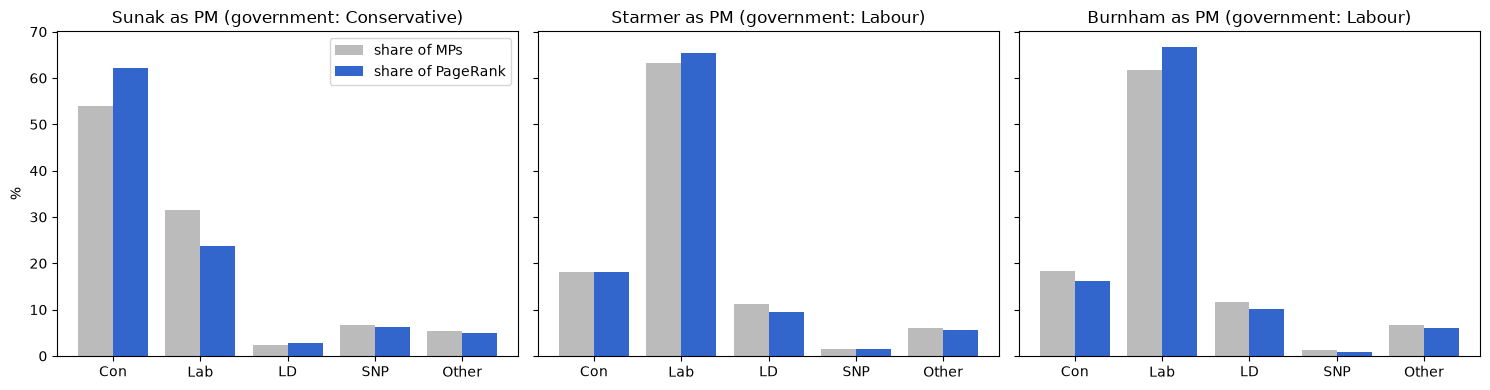

In [20]:
fig, axes = plt.subplots(1, len(PERIODS), figsize=(15, 4), sharey=True)
order = MAIN_PARTIES + ["Other"]
for ax, p in zip(axes, PERIODS):
    s = party_tables[p].reindex(order)
    x = range(len(order))
    ax.bar([i - 0.2 for i in x], s["MP share %"], width=0.4, label="share of MPs", color="#bbbbbb")
    ax.bar([i + 0.2 for i in x], s["pagerank share %"], width=0.4, label="share of PageRank", color="#3366cc")
    ax.set_xticks(list(x))
    ax.set_xticklabels(["Con", "Lab", "LD", "SNP", "Other"])
    ax.set_title(f"{p.capitalize()} as PM (government: {GOVERNMENT[p]})")
axes[0].set_ylabel("%")
axes[0].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "party_pagerank_share.png", dpi=200)
plt.show()

### Party to party

When party X speaks, who speaks next (rows add up to 100).

In [21]:
def party_matrix(period):
    G = graphs[period]
    rows = []
    for a, b, w in G.edges(data="weight"):
        rows.append((G.nodes[a]["group"], G.nodes[b]["group"], w))
    df = pd.DataFrame(rows, columns=["from", "to", "weight"])
    m = df.pivot_table(index="from", columns="to", values="weight", aggfunc="sum", fill_value=0)
    m = m.reindex(index=order, columns=order, fill_value=0)
    return (100 * m.div(m.sum(axis=1), axis=0)).round(1)

for p in PERIODS:
    print(f"--- {p} (government: {GOVERNMENT[p]})")
    print(party_matrix(p).to_string())

--- sunak (government: Conservative)
to                       Conservative  Labour  Liberal Democrat  Scottish National Party  Other
from                                                                                           
Conservative                     54.4    28.5               3.7                      7.7    5.7
Labour                           80.4    13.9               1.4                      2.2    2.2
Liberal Democrat                 80.0    10.1               2.5                      4.1    3.3
Scottish National Party          75.8     8.4               2.0                     11.0    2.8
Other                            75.3    10.8               1.8                      3.5    8.5
--- starmer (government: Labour)
to                       Conservative  Labour  Liberal Democrat  Scottish National Party  Other
from                                                                                           
Conservative                     15.4    77.5               4.0   

### Own side or other side

In [22]:
rows = {}
for p, G in graphs.items():
    same = sum(w for a, b, w in G.edges(data="weight") if G.nodes[a]["party"] == G.nodes[b]["party"])
    rows[p] = {
        "same-party exchanges %": round(100 * same / G.size(weight="weight"), 1),
        "party assortativity": round(nx.attribute_assortativity_coefficient(G, "party"), 3),
        "government-opposition exchanges %": round(100 * sum(
            w for a, b, w in G.edges(data="weight")
            if (G.nodes[a]["party"] == GOVERNMENT[p]) != (G.nodes[b]["party"] == GOVERNMENT[p])
        ) / G.size(weight="weight"), 1),
    }
mixing = pd.DataFrame(rows)
mixing.to_csv(RESULTS_DIR / "party_mixing.csv")
mixing

,sunak,starmer,burnham
same-party exchanges %,37.600,41.80,42.500
party assortativity,-0.053,-0.01,-0.085
government-opposition exchanges %,58.500,54.60,53.600
